# Tahap 3 — Training & Evaluasi: EfficientNet-B0

**Ruang lingkup notebook ini: EfficientNet-B0 saja.** Tugas ini berkelompok — anggota lain melatih
arsitektur berbeda (AlexNet, VGG16, ResNet, MobileNet), dan hasilnya digabung di tahap perbandingan.

Karena itu seluruh logika training ditulis di modul **`training.py`** yang arsitektur-agnostik, bukan
di notebook ini. Perbandingan antar arsitektur hanya sahih kalau split, preprocessing, hyperparameter,
dan cara menghitung metriknya **identik**; kalau tiap anggota menulis loop training sendiri, perbedaan
yang terukur bisa berasal dari perbedaan kode, bukan dari arsitekturnya. Anggota lain cukup mengganti
satu argumen:

```python
model = tr.build_model("resnet18", num_classes=31)   # ganti nama arsitektur saja
```

Hasil tiap arsitektur ditulis ke `results/<nama_model>/` dalam format seragam, siap digabung.

**Prasyarat:** `prepare_data.ipynb` (split + dedup) dan `preprocessing.ipynb` (Tahap 2) sudah dijalankan.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

import data_pipeline as dp
import training as tr

MODEL_NAME = "efficientnet_b0"

# Palet: biru = train, oranye = validation. Dipakai konsisten di semua grafik.
C_TRAIN, C_VAL, C_ACCENT = "#2a78d6", "#eb6834", "#1baf7a"
C_GRID, C_TEXT = "#d8d7d2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_TEXT,
    "xtick.color": C_TEXT, "ytick.color": C_TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
})

dp.seed_everything(dp.SEED)
DEVICE = dp.get_device()
print(f"Device: {DEVICE}")
print(f"Torch : {torch.__version__}")

Device: mps
Torch : 2.15.0


## 2. Tentang EfficientNet-B0

Bagian ini untuk bagian "Penjelasan arsitektur" di laporan.

**Ide utama: compound scaling.** Sebelum EfficientNet, memperbesar CNN dilakukan dengan menaikkan salah
satu dimensi saja — lebih dalam (ResNet), lebih lebar (WideResNet), atau input lebih besar. Tan & Le (2019)
menunjukkan ketiganya saling bergantung, dan menaikkannya bersama-sama dengan rasio tetap
(depth `d=α^φ`, width `w=β^φ`, resolusi `r=γ^φ`) memberi akurasi lebih tinggi pada jumlah FLOPs yang sama.
B0 adalah *baseline* hasil neural architecture search; B1–B7 adalah B0 yang di-scale dengan rumus itu.

**Blok penyusun: MBConv (Mobile Inverted Bottleneck).** Berbeda dari bottleneck ResNet yang menyempit di
tengah, MBConv justru *melebar* dulu (expansion 1×1 conv), lalu memakai **depthwise separable convolution**
— konvolusi spasial per kanal, disusul 1×1 pointwise untuk mencampur kanal. Pemisahan ini memangkas biaya
komputasi sekitar `1/k²` dibanding konvolusi biasa berkernel `k`, dan itulah sebabnya B0 hanya butuh ~4 M
parameter namun akurasinya di ImageNet setara ResNet-50 yang ~24 M.

**Squeeze-and-Excitation (SE).** Tiap blok MBConv punya modul SE: fitur di-pool jadi satu nilai per kanal
("squeeze"), lewat dua layer kecil menghasilkan bobot per kanal ("excitation"), lalu kanal dikalikan bobot
itu. Efeknya model belajar *kanal mana yang penting* untuk input tertentu — bentuk attention antar-kanal
yang murah.

**Aktivasi Swish/SiLU** (`x·sigmoid(x)`) menggantikan ReLU; non-monotonik dan mulus, sedikit lebih baik
pada jaringan dalam.

**Relevansi untuk dataset ini.** 31 kelas rempah dengan hanya ~136 citra train per kelas tergolong
dataset kecil. Model berparameter besar (VGG16 ~134 M) punya risiko overfitting lebih tinggi pada data
sebesar ini, sementara B0 dengan 4 M parameter memberi kapasitas yang lebih proporsional — hipotesis yang
akan diuji oleh hasil perbandingan kelompok nanti.

In [2]:
# Konteks ukuran arsitektur (bobot tidak diunduh, hanya struktur)
baris = []
for name in tr.ARCHITECTURES:
    m = tr.build_model(name, num_classes=31, pretrained=False)
    info = tr.count_parameters(m)
    baris.append({"arsitektur": name,
                  "params (M)": round(info["total_params"] / 1e6, 1),
                  "ukuran (MB)": round(info["size_mb"], 1)})
    del m

konteks = pd.DataFrame(baris).sort_values("params (M)")
print(konteks.to_string(index=False))
print("\n(Baris selain efficientnet_b0 hanya konteks ukuran; pelatihannya bagian anggota kelompok lain.)")

     arsitektur  params (M)  ukuran (MB)
   mobilenet_v2         2.3          9.1
efficientnet_b0         4.0         16.2
       resnet18        11.2         44.8
       resnet50        23.6         94.3
        alexnet        57.1        228.5
          vgg16       134.4        537.6

(Baris selain efficientnet_b0 hanya konteks ukuran; pelatihannya bagian anggota kelompok lain.)


## 3. Data & Model

In [4]:
CONFIG = tr.TrainConfig(
    epochs=5,
    lr=1e-4,
    weight_decay=1e-4,
    batch_size=32,
    patience=5,
    augment="basic",
    use_class_weights=True,
)

loaders, ds = dp.build_dataloaders(
    # num_workers rendah: mesin ini 8 GB, worker tambahan memicu swap yang
    # biayanya jauh lebih besar daripada keuntungan paralelisasi loading.
    batch_size=CONFIG.batch_size, num_workers=2, augment=CONFIG.augment
)
classes = ds["train"].classes

print(f"train/val/test : {len(ds['train'])}/{len(ds['val'])}/{len(ds['test'])}")
print(f"kelas          : {len(classes)}")
print(f"batch per epoch: {len(loaders['train'])}")
print(f"\nHyperparameter (harus sama untuk semua arsitektur yang dibandingkan):")
for k, v in vars(CONFIG).items():
    print(f"  {k:20s}: {v}")

train/val/test : 4221/905/905
kelas          : 31
batch per epoch: 131

Hyperparameter (harus sama untuk semua arsitektur yang dibandingkan):
  epochs              : 5
  lr                  : 0.0001
  weight_decay        : 0.0001
  batch_size          : 32
  label_smoothing     : 0.0
  patience            : 5
  seed                : 42
  augment             : basic
  use_class_weights   : True
  extra               : {}


In [5]:
model = tr.build_model(MODEL_NAME, num_classes=len(classes), pretrained=True)
info = tr.count_parameters(model)

print(f"{MODEL_NAME}: {info['total_params']:,} parameter ({info['total_params']/1e6:.2f} M), "
      f"{info['size_mb']:.1f} MB")
print(f"\nLayer klasifikasi setelah diganti:\n{model.classifier}")

# Seluruh jaringan di-fine-tune, bukan hanya head. Dengan ~4200 citra train,
# fine-tuning penuh memberi akurasi lebih tinggi daripada membekukan backbone,
# dan lr kecil (1e-4) menjaga fitur pretrained tidak rusak di epoch awal.
print(f"\nParameter yang dilatih: {info['trainable_params']:,} (seluruh jaringan, fine-tuning penuh)")

efficientnet_b0: 4,047,259 parameter (4.05 M), 16.2 MB

Layer klasifikasi setelah diganti:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=31, bias=True)
)

Parameter yang dilatih: 4,047,259 (seluruh jaringan, fine-tuning penuh)


## 4. Training

Konfigurasi: AdamW + cosine annealing, `CrossEntropyLoss` berbobot kelas (menangani imbalance 1.73x dari
Tahap 1), early stopping pada **val macro-F1** dengan patience 5.

Dipilih macro-F1, bukan akurasi, sebagai kriteria model terbaik: dengan kelas yang tidak seimbang,
akurasi bisa naik hanya karena model membaik di kelas besar sementara kelas kecil seperti `asam jawa`
(85 citra train) justru memburuk. Macro-F1 memberi bobot sama ke tiap kelas.

**Training dijalankan dari terminal, bukan dari sel notebook:**

```bash
python train_efficientnet.py          # progres tampil live
tail -f logs/efficientnet_b0.log      # atau pantau dari terminal lain
```

Alasannya praktis — output sel notebook baru terlihat setelah selnya selesai, sehingga training belasan
menit berjalan tanpa tanda kehidupan. Skrip mencetak progres per 20 batch lengkap dengan estimasi sisa
waktu. Notebook ini lalu memuat checkpoint dan history hasil run tersebut, jadi grafik di bawah dibuat
tanpa melatih ulang.

Set `RETRAIN = True` kalau memang ingin melatih dari sel notebook — progres tiap epoch tampil sebagai
progress bar (batch ke-berapa, loss berjalan, estimasi sisa waktu), lalu satu baris ringkasan per epoch.

In [6]:
RETRAIN = False   # True = latih ulang dari notebook (progress bar per epoch tampil di output sel)

sudah_ada = (Path("results") / MODEL_NAME / "history.json").exists()

if RETRAIN or not sudah_ada:
    if not sudah_ada:
        print("Hasil training belum ada. Disarankan jalankan dulu dari terminal:\n"
              "    python train_efficientnet.py\n"
              "Melanjutkan dengan training dari notebook...\n")
    t0 = time.perf_counter()
    hasil = tr.fit(model, loaders, ds, model_name=MODEL_NAME, config=CONFIG, device=DEVICE)
    print(f"\nTotal waktu training: {(time.perf_counter() - t0)/60:.1f} menit")
else:
    hasil = tr.load_run(MODEL_NAME, model, device=DEVICE)
    print(f"Memuat hasil training tersimpan (dari train_efficientnet.py).")
    print(f"Jalankan ulang dengan RETRAIN = True kalau ingin melatih dari awal.\n")

print(f"Epoch dijalankan : {len(hasil['history'])}")
print(f"Epoch terbaik    : {hasil['best_epoch']} (val macro-F1 {hasil['best_val_macro_f1']:.4f})")
print(f"Waktu training   : {hasil['total_train_time_s']/60:.1f} menit")
print(f"Checkpoint       : {hasil['checkpoint']}")

Hasil training belum ada. Disarankan jalankan dulu dari terminal:
    python train_efficientnet.py
Melanjutkan dengan training dari notebook...

epoch 1/5 train:  76%|███████▌  | 99/131 [03:42<01:26,  2.71s/batch, loss=2.7358]

/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 1/5 val  :   0%|          | 0/29 [00:00<?, ?batch/s]

Python(2659) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(2660) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


epoch  1/5  train loss 2.4483 acc 0.4993  |  val loss 1.0748 acc 0.8077 F1 0.8013  (288s+28s)  *best
epoch 2/5 train: 100%|██████████| 131/131 [05:22<00:00,  2.46s/batch, loss=0.8771]
epoch  2/5  train loss 0.8771 acc 0.8177  |  val loss 0.5122 acc 0.8895 F1 0.8878  (323s+10s)  *best
epoch 3/5 train: 100%|██████████| 131/131 [06:10<00:00,  2.82s/batch, loss=0.5030]
epoch  3/5  train loss 0.5030 acc 0.8822  |  val loss 0.3667 acc 0.9094 F1 0.9085  (370s+10s)  *best
epoch 4/5 train: 100%|██████████| 131/131 [04:55<00:00,  2.26s/batch, loss=0.3888]
epoch  4/5  train loss 0.3888 acc 0.9062  |  val loss 0.3213 acc 0.9193 F1 0.9184  (296s+16s)  *best
epoch 5/5 train: 100%|██████████| 131/131 [04:26<00:00,  2.03s/batch, loss=0.3336]
epoch  5/5  train loss 0.3336 acc 0.9163  |  val loss 0.3084 acc 0.9227 F1 0.9217  (266s+10s)  *best

Total waktu training: 27.0 menit
Epoch dijalankan : 5
Epoch terbaik    : 5 (val macro-F1 0.9217)
Waktu training   : 27.0 menit
Checkpoint       : /Users/akbarrzql

### 4.1 Kurva Belajar

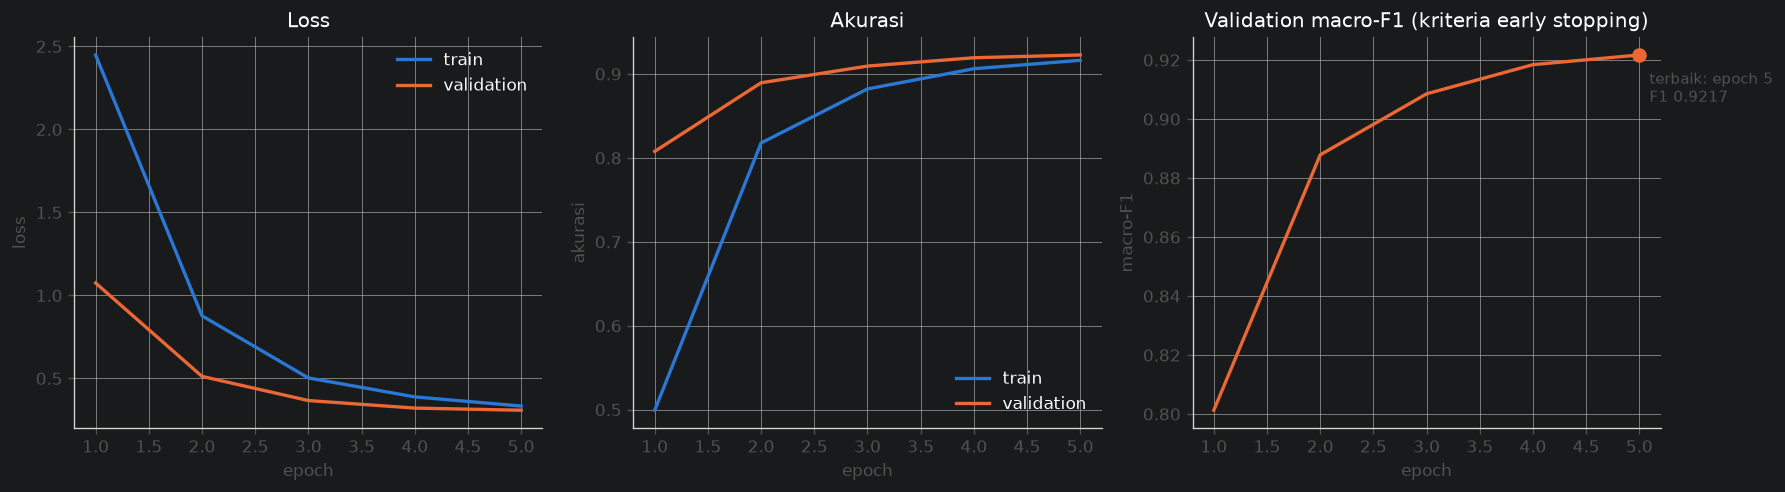

 epoch  train_loss  train_acc  val_loss  val_acc  val_macro_f1  train_time_s
     1      2.4483     0.4993    1.0748   0.8077        0.8013      288.4044
     2      0.8771     0.8177    0.5122   0.8895        0.8878      322.6941
     3      0.5030     0.8822    0.3667   0.9094        0.9085      370.2642
     4      0.3888     0.9062    0.3213   0.9193        0.9184      295.7854
     5      0.3336     0.9163    0.3084   0.9227        0.9217      266.2274

Gap train-val akurasi di epoch terbaik: -0.0064
Gap besar (>0.10) menandakan overfitting -> pertimbangkan augment='strong'.


In [7]:
hist = pd.DataFrame(hasil["history"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(hist["epoch"], hist["train_loss"], color=C_TRAIN, lw=2, label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], color=C_VAL, lw=2, label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend(frameon=False)

axes[1].plot(hist["epoch"], hist["train_acc"], color=C_TRAIN, lw=2, label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], color=C_VAL, lw=2, label="validation")
axes[1].set(xlabel="epoch", ylabel="akurasi", title="Akurasi")
axes[1].legend(frameon=False)

axes[2].plot(hist["epoch"], hist["val_macro_f1"], color=C_VAL, lw=2)
best = hasil["best_epoch"]
best_f1 = hasil["best_val_macro_f1"]
axes[2].scatter([best], [best_f1], color=C_VAL, s=60, zorder=5)
axes[2].annotate(f"terbaik: epoch {best}\nF1 {best_f1:.4f}",
                 xy=(best, best_f1), xytext=(6, -28), textcoords="offset points",
                 fontsize=9, color=C_TEXT)
axes[2].set(xlabel="epoch", ylabel="macro-F1", title="Validation macro-F1 (kriteria early stopping)")

plt.tight_layout()
plt.show()

print(hist[["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "train_time_s"]]
      .round(4).to_string(index=False))

gap = hist.loc[hist["epoch"] == best, "train_acc"].iloc[0] - hist.loc[hist["epoch"] == best, "val_acc"].iloc[0]
print(f"\nGap train-val akurasi di epoch terbaik: {gap:+.4f}")
print("Gap besar (>0.10) menandakan overfitting -> pertimbangkan augment='strong'.")

## 5. Evaluasi pada Test Set

Test set baru disentuh **sekali, di sini**, memakai checkpoint terbaik yang dipilih berdasarkan
validation. Memilih model berdasarkan skor test akan membuat angka test tidak lagi menjadi estimasi
jujur terhadap data baru.

In [8]:
evalres = tr.evaluate(model, loaders, ds, model_name=MODEL_NAME, hasil_fit=hasil, device=DEVICE)
m = evalres["metrics"]

print(f"=== {MODEL_NAME} — hasil test ===\n")
ringkas = pd.DataFrame([
    ("Accuracy", m["accuracy"]),
    ("Top-5 accuracy", m["top5_accuracy"]),
    ("Precision (macro)", m["precision_macro"]),
    ("Recall (macro)", m["recall_macro"]),
    ("F1 (macro)", m["f1_macro"]),
    ("Precision (weighted)", m["precision_weighted"]),
    ("Recall (weighted)", m["recall_weighted"]),
    ("F1 (weighted)", m["f1_weighted"]),
], columns=["metrik", "nilai"])
print(ringkas.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\nSelisih val macro-F1 ({hasil['best_val_macro_f1']:.4f}) vs test macro-F1 ({m['f1_macro']:.4f}): "
      f"{m['f1_macro'] - hasil['best_val_macro_f1']:+.4f}")
print(f"Hasil disimpan ke: {evalres['output_dir']}")

Python(4280) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(4281) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


=== efficientnet_b0 — hasil test ===

              metrik  nilai
            Accuracy 0.9403
      Top-5 accuracy 0.9923
   Precision (macro) 0.9412
      Recall (macro) 0.9402
          F1 (macro) 0.9394
Precision (weighted) 0.9425
   Recall (weighted) 0.9403
       F1 (weighted) 0.9401

Selisih val macro-F1 (0.9217) vs test macro-F1 (0.9394): +0.0177
Hasil disimpan ke: /Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/results/efficientnet_b0


### 5.1 Metrik per Kelas

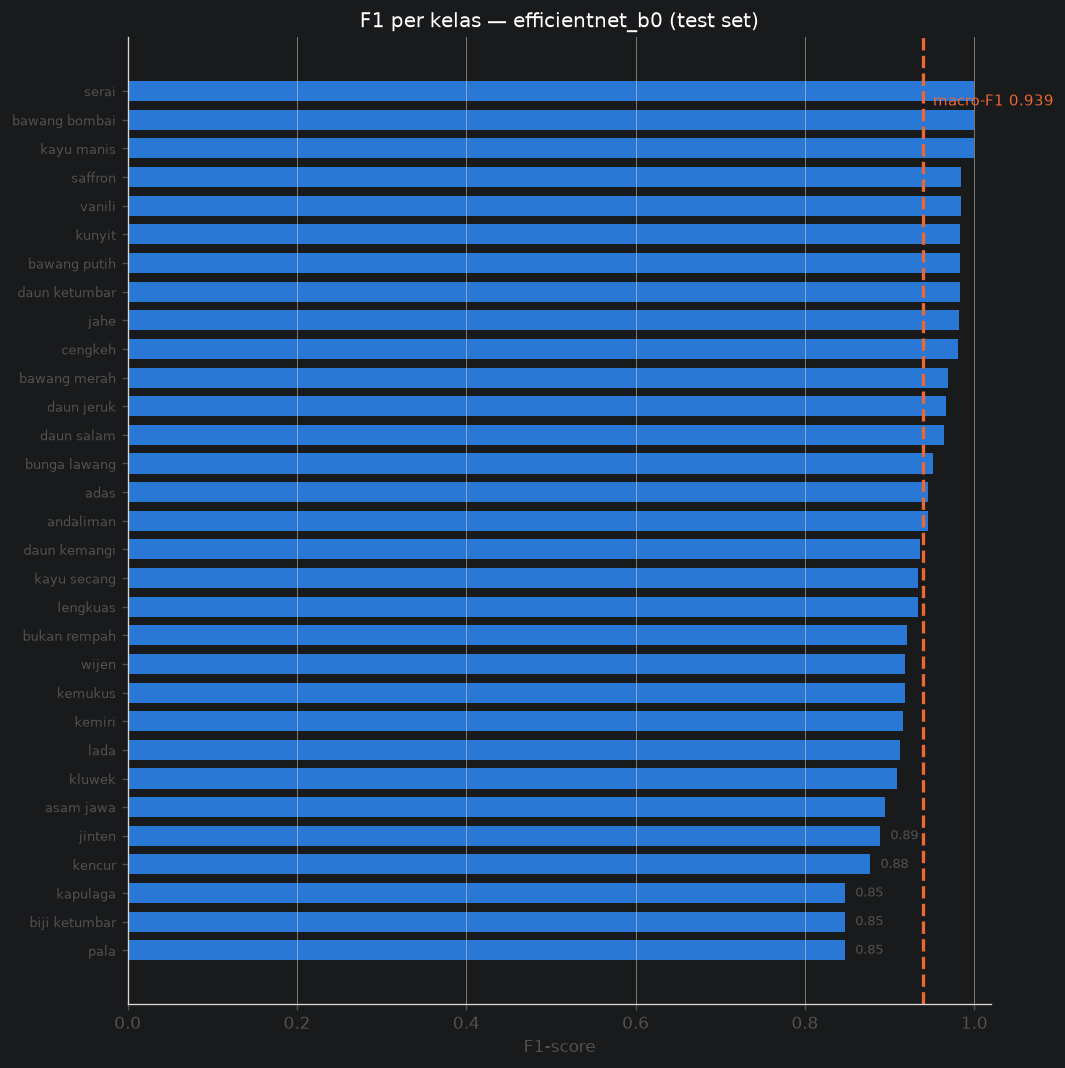

5 kelas terlemah:
        class  precision  recall     f1  support
         pala     0.8929  0.8065 0.8475       31
biji ketumbar     0.8065  0.8929 0.8475       28
     kapulaga     0.8929  0.8065 0.8475       31
       kencur     0.9259  0.8333 0.8772       30
       jinten     0.8571  0.9231 0.8889       26

5 kelas terkuat:
        class  precision  recall     f1  support
       vanili     0.9688     1.0 0.9841       31
      saffron     0.9688     1.0 0.9841       31
   kayu manis     1.0000     1.0 1.0000       31
bawang bombai     1.0000     1.0 1.0000       31
        serai     1.0000     1.0 1.0000       29


In [9]:
per_class = pd.DataFrame(evalres["per_class"]).sort_values("f1")

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(per_class))
ax.barh(y, per_class["f1"], color=C_TRAIN, height=0.7)
ax.set_yticks(y)
ax.set_yticklabels(per_class["class"], fontsize=8)
ax.axvline(m["f1_macro"], color=C_VAL, lw=2, ls="--")
ax.annotate(f"macro-F1 {m['f1_macro']:.3f}", xy=(m["f1_macro"], len(per_class) - 1.5),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=C_VAL)
ax.set(xlabel="F1-score", xlim=(0, 1.02), title=f"F1 per kelas — {MODEL_NAME} (test set)")
ax.grid(axis="y", visible=False)
# Label langsung pada 5 kelas terlemah: bagian yang paling perlu dibaca angkanya
for i in range(5):
    ax.text(per_class["f1"].iloc[i] + 0.012, i, f"{per_class['f1'].iloc[i]:.2f}",
            va="center", fontsize=8, color=C_TEXT)
plt.tight_layout()
plt.show()

print("5 kelas terlemah:")
print(per_class.head(5)[["class", "precision", "recall", "f1", "support"]]
      .round(4).to_string(index=False))
print("\n5 kelas terkuat:")
print(per_class.tail(5)[["class", "precision", "recall", "f1", "support"]]
      .round(4).to_string(index=False))

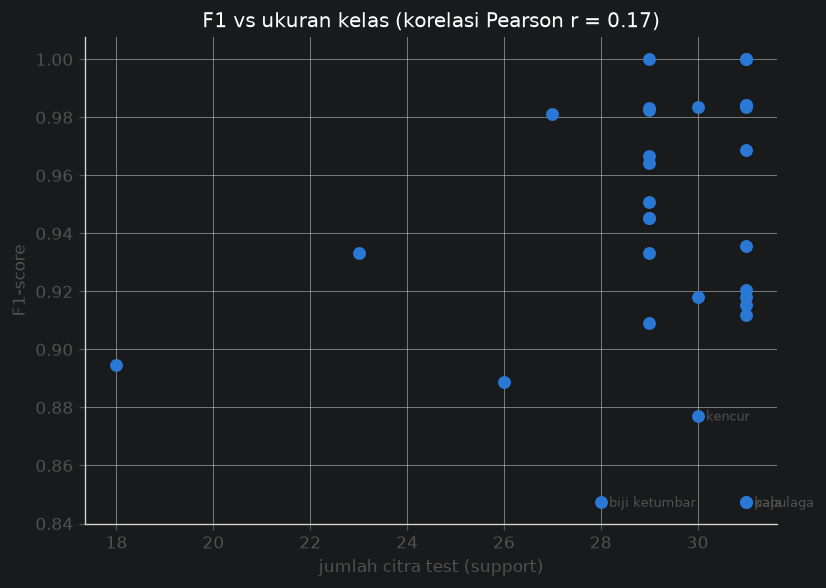

Korelasi support vs F1: r = 0.173
r mendekati 0 berarti kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.


In [10]:
# Apakah kelas kecil memang lebih sulit? Relevan karena Tahap 1 menemukan
# imbalance 1.73x setelah dedup.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_class["support"], per_class["f1"], color=C_TRAIN, s=45, zorder=3)
for _, r in per_class.head(4).iterrows():
    ax.annotate(r["class"], xy=(r["support"], r["f1"]), xytext=(5, -3),
                textcoords="offset points", fontsize=8, color=C_TEXT)
korelasi = per_class["support"].corr(per_class["f1"])
ax.set(xlabel="jumlah citra test (support)", ylabel="F1-score",
       title=f"F1 vs ukuran kelas (korelasi Pearson r = {korelasi:.2f})")
plt.tight_layout()
plt.show()
print(f"Korelasi support vs F1: r = {korelasi:.3f}")
print("r mendekati 0 berarti kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.")

### 5.2 Confusion Matrix

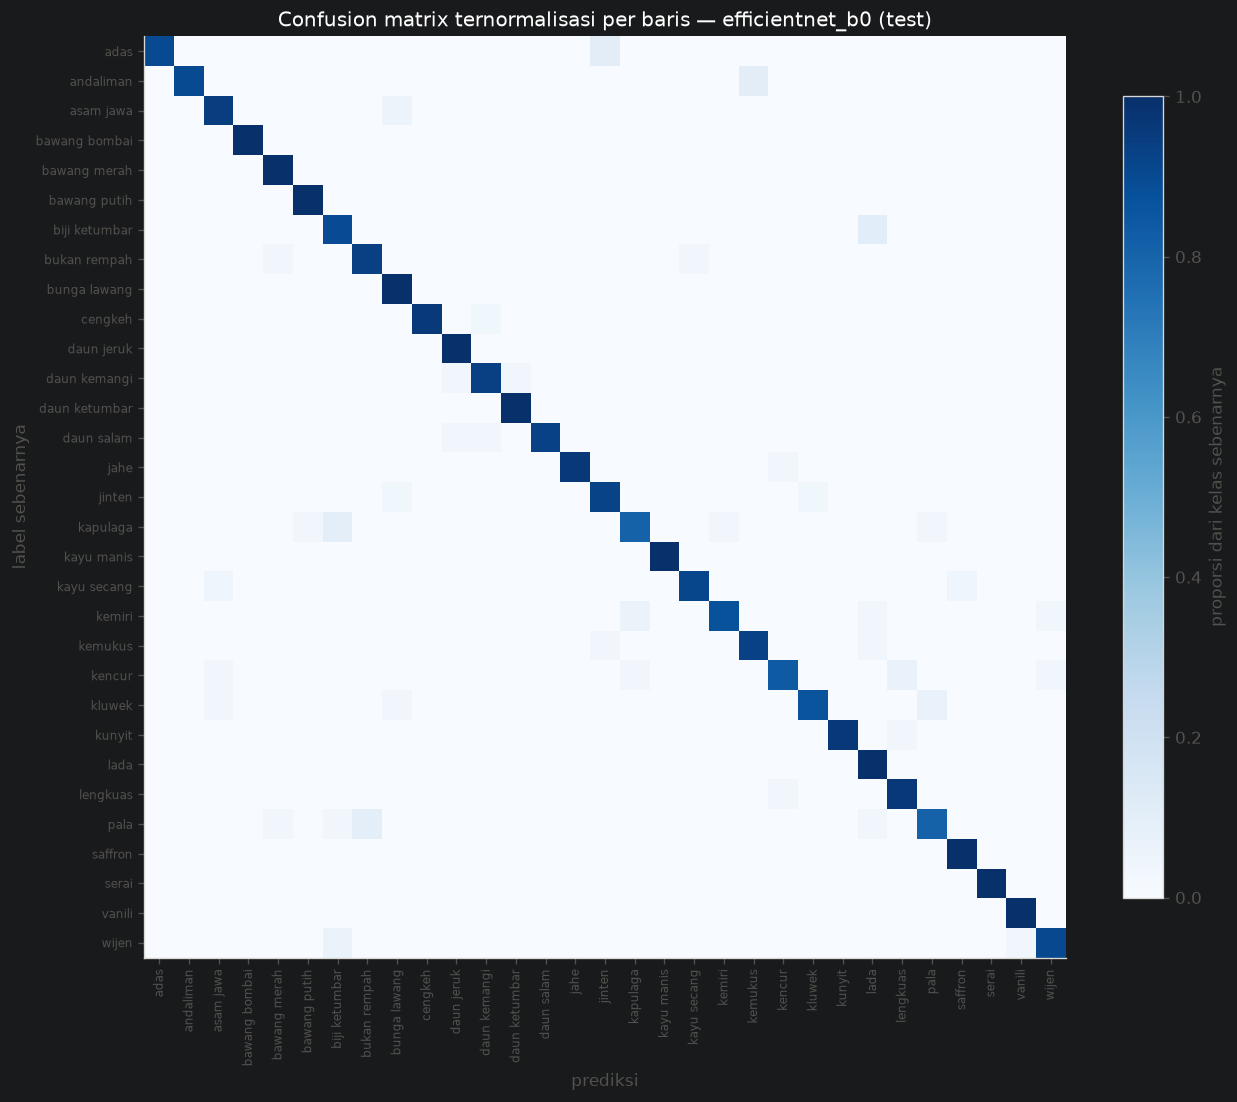

15 kebingungan terbesar:
   sebenarnya    diprediksi  n  proporsi
         adas        jinten  3     0.103
    andaliman       kemukus  3     0.103
biji ketumbar          lada  3     0.107
     kapulaga biji ketumbar  3     0.097
         pala  bukan rempah  3     0.097
       kemiri      kapulaga  2     0.065
       kencur      lengkuas  2     0.067
       kluwek          pala  2     0.069
        wijen biji ketumbar  2     0.065
    asam jawa  bunga lawang  1     0.056
 bukan rempah  bawang merah  1     0.032
 bukan rempah   kayu secang  1     0.032
      cengkeh  daun kemangi  1     0.037
 daun kemangi    daun jeruk  1     0.032
 daun kemangi daun ketumbar  1     0.032

Total salah klasifikasi: 54 dari 905 citra test


In [11]:
cm = evalres["confusion_matrix"]
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9.5))
# Sequential satu hue (terang -> gelap) untuk besaran; bukan rainbow.
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=7)
ax.set_yticklabels(classes, fontsize=7)
ax.set(xlabel="prediksi", ylabel="label sebenarnya",
       title=f"Confusion matrix ternormalisasi per baris — {MODEL_NAME} (test)")
ax.grid(visible=False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("proporsi dari kelas sebenarnya", color=C_TEXT)
plt.tight_layout()
plt.show()

# Daftar kebingungan terbesar lebih terbaca daripada mencari sel gelap satu per satu
salah = [(classes[i], classes[j], cm[i, j], cm_norm[i, j])
         for i in range(len(classes)) for j in range(len(classes))
         if i != j and cm[i, j] > 0]
salah.sort(key=lambda t: -t[2])

konfusi = pd.DataFrame(salah[:15], columns=["sebenarnya", "diprediksi", "n", "proporsi"])
print("15 kebingungan terbesar:")
print(konfusi.round(3).to_string(index=False))
print(f"\nTotal salah klasifikasi: {int(cm.sum() - np.trace(cm))} dari {int(cm.sum())} citra test")

### 5.3 Analisis Kesalahan

Jumlah salah: 54 (5.97%)
Rata-rata confidence saat BENAR : 0.8734
Rata-rata confidence saat SALAH : 0.5291

Model yang terkalibrasi baik seharusnya kurang yakin ketika salah.


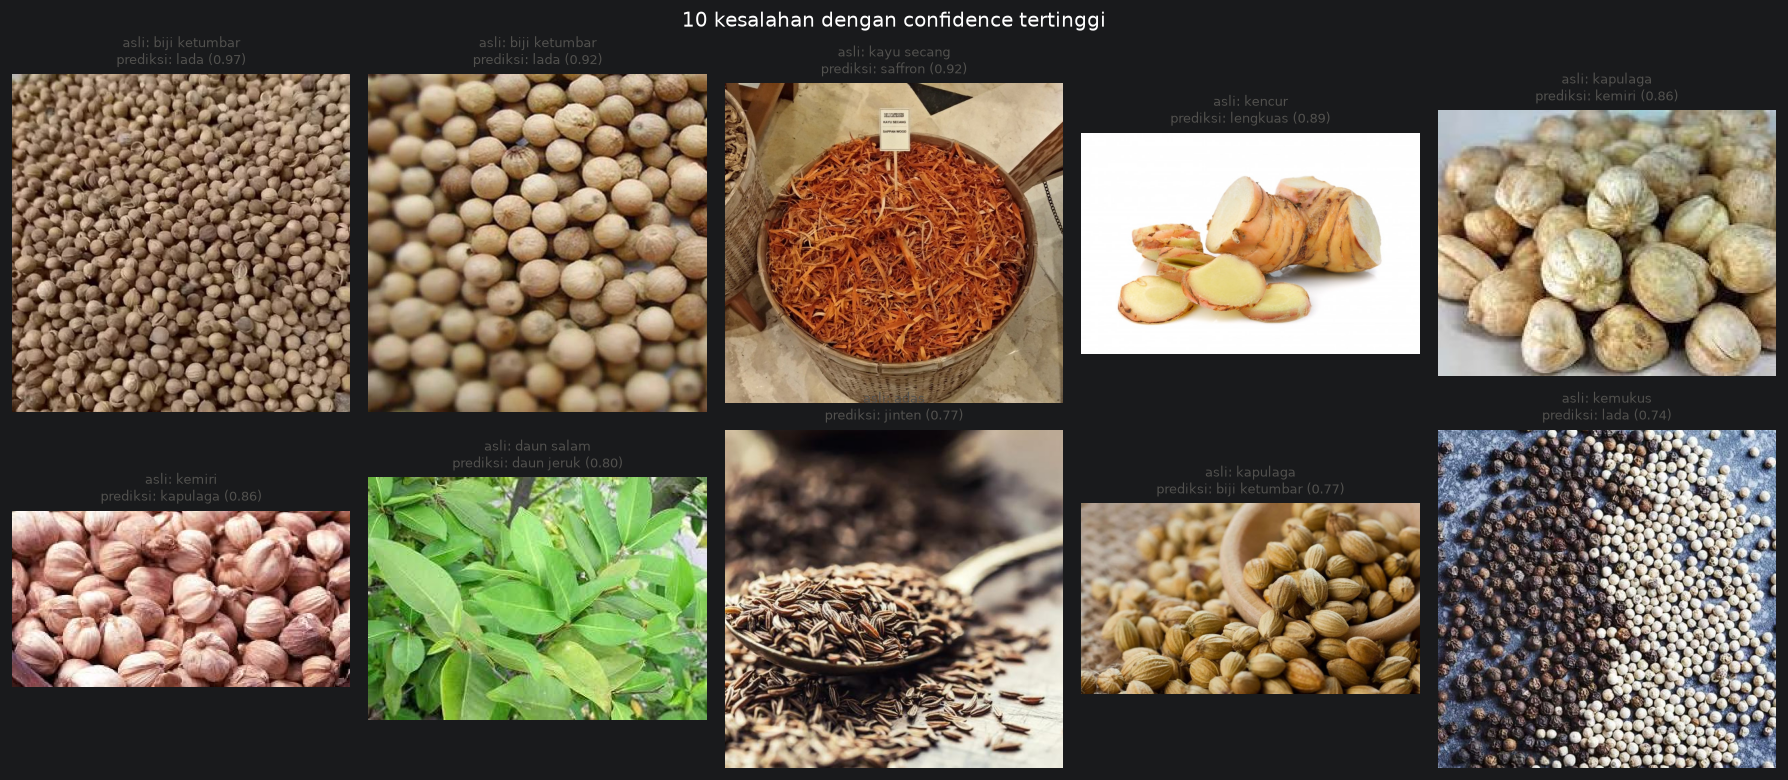

In [12]:
probs, preds, trues = evalres["probs"], evalres["preds"], evalres["trues"]
paths = [p for p, _ in ds["test"].samples]

salah_idx = np.where(preds != trues)[0]
conf = probs[np.arange(len(preds)), preds]

print(f"Jumlah salah: {len(salah_idx)} ({len(salah_idx)/len(preds):.2%})")
print(f"Rata-rata confidence saat BENAR : {conf[preds == trues].mean():.4f}")
print(f"Rata-rata confidence saat SALAH : {conf[salah_idx].mean():.4f}")
print("\nModel yang terkalibrasi baik seharusnya kurang yakin ketika salah.")

# Kesalahan paling percaya diri = kandidat label salah atau kelas yang benar-benar mirip
urut = salah_idx[np.argsort(-conf[salah_idx])][:10]
fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, i in zip(axes.ravel(), urut):
    ax.imshow(Image.open(paths[i]).convert("RGB"))
    ax.set_title(f"asli: {classes[trues[i]]}\nprediksi: {classes[preds[i]]} ({conf[i]:.2f})",
                 fontsize=8, color=C_TEXT)
    ax.axis("off")
fig.suptitle("10 kesalahan dengan confidence tertinggi")
plt.tight_layout()
plt.show()

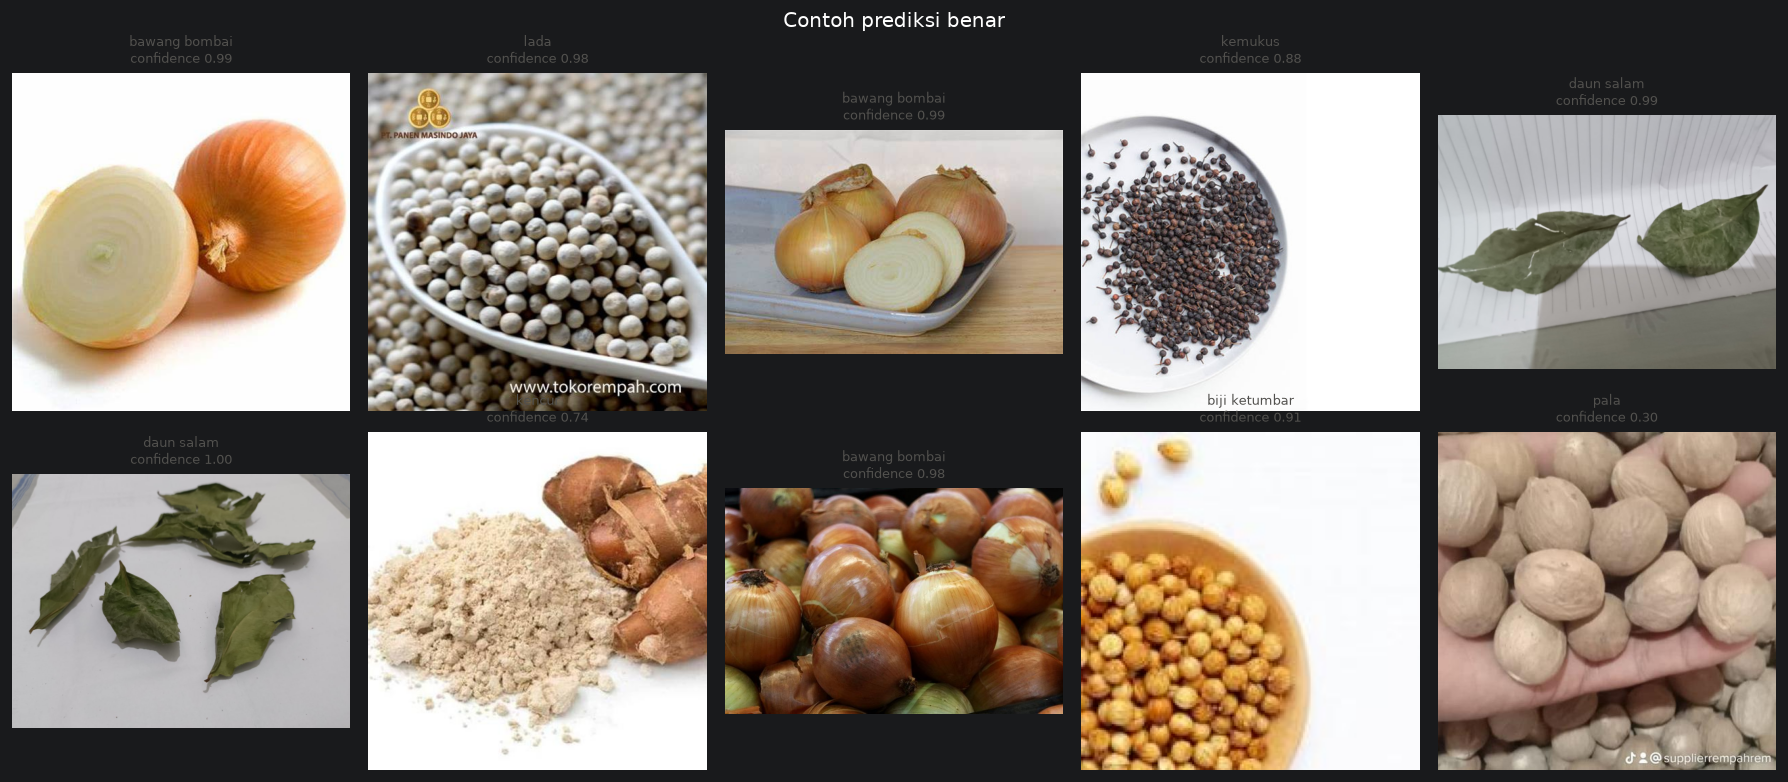

In [13]:
# Prediksi benar dari model terbaik, sesuai permintaan tugas langkah 5
rng = np.random.default_rng(dp.SEED)
benar_idx = np.where(preds == trues)[0]
pilih = rng.choice(benar_idx, 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, i in zip(axes.ravel(), pilih):
    ax.imshow(Image.open(paths[i]).convert("RGB"))
    ax.set_title(f"{classes[preds[i]]}\nconfidence {conf[i]:.2f}", fontsize=8, color=C_TEXT)
    ax.axis("off")
fig.suptitle("Contoh prediksi benar")
plt.tight_layout()
plt.show()

## 6. Efisiensi Komputasi

In [14]:
eff = pd.DataFrame([
    ("Jumlah parameter", f"{m['total_params']:,} ({m['total_params']/1e6:.2f} M)"),
    ("Ukuran model", f"{m['size_mb']:.1f} MB"),
    ("Epoch dijalankan", f"{m['epochs_run']} (terbaik: epoch {m['best_epoch']})"),
    ("Waktu training total", f"{m['total_train_time_s']/60:.1f} menit"),
    ("Rata-rata waktu/epoch", f"{m['mean_epoch_time_s']:.1f} detik"),
    ("Latensi inferensi", f"{m['infer_latency_ms_per_batch']:.1f} ms/batch "
                          f"({m['infer_latency_ms_per_image']:.2f} ms/citra)"),
    ("Throughput inferensi", f"{m['infer_throughput_img_per_s']:.0f} citra/detik"),
    ("Device", f"{m['device']} — {m['platform']}"),
], columns=["metrik", "nilai"])
print(eff.to_string(index=False))

print(f"\nAkurasi per juta parameter: {m['accuracy'] / (m['total_params']/1e6):.4f}")
print("Angka ini berguna untuk membandingkan efisiensi arsitektur di tahap perbandingan kelompok.")

               metrik                          nilai
     Jumlah parameter             4,047,259 (4.05 M)
         Ukuran model                        16.2 MB
     Epoch dijalankan           5 (terbaik: epoch 5)
 Waktu training total                     27.0 menit
Rata-rata waktu/epoch                    308.7 detik
    Latensi inferensi 101.0 ms/batch (3.16 ms/citra)
 Throughput inferensi                317 citra/detik
               Device     mps — arm64 / torch 2.15.0

Akurasi per juta parameter: 0.2323
Angka ini berguna untuk membandingkan efisiensi arsitektur di tahap perbandingan kelompok.


## 7. Ekspor Hasil untuk Perbandingan Kelompok

In [15]:
out_dir = Path(evalres["output_dir"])
print(f"Isi {out_dir}:")
for f in sorted(out_dir.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size/1024:8.1f} KB")

print(f"""
Anggota kelompok lain menjalankan hal yang sama dengan mengganti satu baris:

    MODEL_NAME = "resnet18"      # atau alexnet / vgg16 / mobilenet_v2 / resnet50

SYARAT agar perbandingannya sahih — semuanya sudah otomatis lewat modul:
  - data_split/ yang sama (hasil dedup, {m['n_train']}/{m['n_val']}/{m['n_test']})
  - dp.build_dataloaders() yang sama (224x224, normalisasi ImageNet, augment="{CONFIG.augment}")
  - TrainConfig yang sama (lr={CONFIG.lr}, epochs={CONFIG.epochs}, batch={CONFIG.batch_size})
  - metrik dihitung oleh tr.evaluate() yang sama

CATATAN: VGG16 tidak muat di batch 32 pada mesin 8 GB (out of memory). Kalau anggota lain
harus menurunkan batch size, hal itu WAJIB dicatat di laporan — waktu training antar arsitektur
jadi tidak apple-to-apple, meski metrik akurasinya tetap bisa dibandingkan.

Tahap perbandingan nanti cukup memanggil:
    tr.load_results("efficientnet_b0"), tr.load_results("resnet18"), ...
""")

Isi /Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/results/efficientnet_b0:
  classification_report.txt         1.9 KB
  confusion_matrix.csv              2.2 KB
  history.json                      1.5 KB
  metrics.json                      1.1 KB
  per_class.json                    2.6 KB
  test_preds.npy                    7.2 KB
  test_probs.npy                  109.7 KB
  test_true.npy                     7.2 KB

Anggota kelompok lain menjalankan hal yang sama dengan mengganti satu baris:

    MODEL_NAME = "resnet18"      # atau alexnet / vgg16 / mobilenet_v2 / resnet50

SYARAT agar perbandingannya sahih — semuanya sudah otomatis lewat modul:
  - data_split/ yang sama (hasil dedup, 4221/905/905)
  - dp.build_dataloaders() yang sama (224x224, normalisasi ImageNet, augment="basic")
  - TrainConfig yang sama (lr=0.0001, epochs=5, batch=32)
  - metrik dihitung oleh tr.evaluate() yang sama

CATATAN: VGG16 tidak muat di batch 32 pada mesin 8 GB (out of memory). Kalau anggota lai

In [16]:
# Ringkasan satu baris, siap digabung jadi tabel perbandingan di laporan
ringkasan_baris = {
    "arsitektur": MODEL_NAME,
    "params_M": round(m["total_params"] / 1e6, 2),
    "accuracy": round(m["accuracy"], 4),
    "precision_macro": round(m["precision_macro"], 4),
    "recall_macro": round(m["recall_macro"], 4),
    "f1_macro": round(m["f1_macro"], 4),
    "train_time_min": round(m["total_train_time_s"] / 60, 1),
    "infer_ms_per_image": round(m["infer_latency_ms_per_image"], 2),
}
print(pd.DataFrame([ringkasan_baris]).to_string(index=False))

Path("results").mkdir(exist_ok=True)
pd.DataFrame([ringkasan_baris]).to_csv(f"results/{MODEL_NAME}/summary_row.csv", index=False)
print(f"\nDisimpan: results/{MODEL_NAME}/summary_row.csv")

     arsitektur  params_M  accuracy  precision_macro  recall_macro  f1_macro  train_time_min  infer_ms_per_image
efficientnet_b0      4.05    0.9403           0.9412        0.9402    0.9394            27.0                3.16

Disimpan: results/efficientnet_b0/summary_row.csv


## 8. Ringkasan

Isi setelah melihat hasil di atas — poin-poin ini yang masuk ke laporan:

- **Performa.** Akurasi dan macro-F1 test, serta selisihnya terhadap validation (selisih besar
  menandakan model ter-overfit ke validation lewat early stopping).
- **Kelas tersulit.** Lihat 5 kelas ber-F1 terendah dan tabel kebingungan terbesar. Periksa apakah
  pasangan yang tertukar memang mirip secara visual — itu keterbatasan data/kelas, bukan kegagalan
  arsitektur.
- **Keterbatasan data yang sudah diketahui dari Tahap 1:** 11% citra ter-upsample dari resolusi di
  bawah 224 px, dan kelas `asam jawa` hanya punya 85 citra train setelah dedup. Keduanya membatasi
  akurasi maksimum dan perlu disebut di laporan.
- **Efisiensi.** 4 M parameter dengan waktu training dan latensi inferensi di tabel Bagian 6 — ini
  yang akan dikontraskan dengan VGG16 (134 M) dan AlexNet (57 M) milik anggota lain.
- **Hipotesis untuk perbandingan:** pada dataset kecil (~136 citra train/kelas), arsitektur
  berparameter besar belum tentu unggul; EfficientNet-B0 diperkirakan kompetitif dengan biaya
  komputasi jauh lebih rendah. Hipotesis ini baru bisa diuji setelah hasil anggota lain masuk.